## Projeto Integrador Interdisciplinar II — Terra Signal (DATABRICKS)

**Terra Signal** é uma empresa fictícia do setor de telecomunicações, iremos usar a base 'history.csv' que contém informações sobre sua carteira histórica de cliente, a Base contém 5634 linhas e 23 colunas.

Nosso objeto é analisar os dados e identificar variáveis que relacionam com o cancelamento.

Objetivos Específicos
1. Avaliar a qualidade dos dados e realizar os tratamentos necessários, processar os dados nas camadas **Bronze, Silver e Gold**.
3. Organizar o armazenamento e conduzir a análise exploratória, estatística descritiva e visualizações.
5. Investigar as características da carteira e o histórico de cancelamentos.


## Camada Bronze

### Dicionário de dados

Primeiro vamos definir o dicionários de dados:

**Quantidade de Linhas:** 5634

**Quantidade de Colunas:** 23

| Variáveis | Definição | Unidade | Tipagem | Tipagem Correta |
| --- | --- | --- | --- | --- |
| customerID (id_cliente) | Identificador único de cada cliente | Texto / Código | str | Category |
| gender (genero) | Gênero do cliente | Masculino ou Feminino | str | Category |
| SeniorCitizen (idoso) | Indica se o cliente é idoso | Binário (0 ou 1) | int64 | int64 |
| Partner (possui_parceiro) | Indica se o cliente é casado(a) | Sim ou Não | str | Category |
| Dependents (possui_dependentes) | Indica se o cliente possui dependentes | Sim ou Não | str | Category |
| MonthlyIncome (renda_mensal) | Renda mensal do cliente | Dólares ($) | int64 | int64 |
| tenure (tempo_de_contrato) | Tempo de permanência do cliente na empresa | Meses | str | int64 |
| Contract (tipo_de_contrato) | Tipo de contrato de fidelidade do cliente | Mensal, anual ou bianual | str | Category |
| PaperlessBilling (faturamento_digital) | Indica se o cliente optou por fatura digital | Sim ou Não | str | Category |
| PaymentMethod (metodo_pagamento) | Método de pagamento utilizado | Texto / Categoria | str | Category |
| PhoneService (servico_telefonico) | Indica se o cliente possui serviço de telefone | Sim ou Não | str | Category |
| MultipleLines (multiplas_linhas) | Indica se o cliente possui múltiplas linhas telefônicas | Sim, Não ou Sem telefone | str | Category |
| InternetService (servico_de_internet) | Tipo de serviço de internet contratado | DSL, fibra óptica ou nenhum | str | Category |
| OnlineSecurity (seguranca_online) | Serviço adicional de segurança online | Sim, Não ou Sem internet | str | Category |
| OnlineBackup (backup_online) | Serviço adicional de backup online | Sim, Não ou Sem internet | str | Category |
| DeviceProtection (protecao_de_dispositivos) | Serviço adicional de proteção de dispositivos | Sim, Não ou Sem internet | str | Category |
| TechSupport (suporte_tecnico) | Serviço adicional de suporte técnico | Sim, Não ou Sem internet | str | Category |
| StreamingTV (streaming_de_tv) | Assinatura de serviço de entretenimento por streaming de TV | Sim, Não ou Sem internet | str | Category |
| StreamingMovies (streaming_de_filmes) | Assinatura de serviço de entretenimento por streaming de filmes | Sim, Não ou Sem internet | str | Category |
| MonthlyCharges (cobranca_mensal) | Valor cobrado do cliente na fatura mensal | Dólares ($) | float64 | float64 |
| TotalCharges (cobranca_total) | Valor total acumulado cobrado ao longo da assinatura | Dólares ($) | float64 | float64 |
| Churn (cancelou_contrato) | Indica se o cliente cancelou o serviço | Sim ou Não | str | Category |
| CustomerFeedback (feedback_do_cliente) | Comentários avaliativos dos clientes da empresa | Texto | str | String |

### Carregando os dados e identificando linhas, colunas e tipo de dados

In [68]:
%pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [69]:
import pandas as pd

In [70]:
# Carregando Banco de Dados 
# Instala o motor necessário para leitura de arquivos .csv
df_carteira_cliente = pd.read_csv("DATA/history (1).csv")


In [71]:
df_carteira_cliente.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   str    
 1   gender            5634 non-null   str    
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   str    
 4   Dependents        5634 non-null   str    
 5   tenure            5634 non-null   str    
 6   PhoneService      5634 non-null   str    
 7   MultipleLines     5634 non-null   str    
 8   InternetService   5634 non-null   str    
 9   OnlineSecurity    5634 non-null   str    
 10  OnlineBackup      5634 non-null   str    
 11  DeviceProtection  5634 non-null   str    
 12  TechSupport       5634 non-null   str    
 13  StreamingTV       5634 non-null   str    
 14  StreamingMovies   5634 non-null   str    
 15  Contract          5634 non-null   str    
 16  PaperlessBilling  5634 non-null   str    
 17  Paymen

In [72]:
df_carteira_cliente.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691


In [73]:
df_carteira_cliente.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904
5633,3915-ODIYG,Male,1,No,No,60,Yes,Yes,DSL,Yes,...,No,Yes,One year,Yes,Electronic check,71.75,4374.55,No,I have been a loyal customer of this internet ...,3016


In [74]:
df_carteira_cliente.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'CustomerFeedback', 'MonthlyIncome'],
      dtype='str')

In [75]:
df_carteira_cliente_traduzido = df_carteira_cliente.copy()
df_carteira_cliente_traduzido = df_carteira_cliente_traduzido.rename(columns={
        'customerID': "id_cliente", 
        'gender': "genero", 
        'SeniorCitizen': "idoso", 
        'Partner': "possui_parceiro", 
        'Dependents': "possui_dependentes",
        'tenure': "tempo_de_contrato", 
        'PhoneService': "servico_telefonico", 
        'MultipleLines': "multiplas_linhas", 
        'InternetService': "servico_de_internet",
        'OnlineSecurity': "seguraca_online", 
        'OnlineBackup': "backup_online", 
        'DeviceProtection': "protecao_de_dispositivos", 
        'TechSupport': "suporte_tecnico",
        'StreamingTV': "streaming_de_tv", 
        'StreamingMovies': "streaming_de_filmes", 
        'Contract': "tipo_de_contrato", 
        'PaperlessBilling': "faturamento_digital",
        'PaymentMethod': "metodo_pagamento", 
        'MonthlyCharges': "cobranca_mensal", 
        'TotalCharges': "cobranca_total", 
        'Churn': "cancelou_contrato",
        'CustomerFeedback': "feedback_cliente", 
        'MonthlyIncome': "renda_mensal"
    }) 

In [76]:
df_carteira_cliente_traduzido.head()

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691


### Identificando o numero de variaveis Object

In [77]:
object_cols = df_carteira_cliente_traduzido.select_dtypes(include="object").columns.tolist() 
print('Total de variáveis do tipo Object:',len(object_cols))
print("---------------------------------------------")
print(object_cols)

Total de variáveis do tipo Object: 19
---------------------------------------------
['id_cliente', 'genero', 'possui_parceiro', 'possui_dependentes', 'tempo_de_contrato', 'servico_telefonico', 'multiplas_linhas', 'servico_de_internet', 'seguraca_online', 'backup_online', 'protecao_de_dispositivos', 'suporte_tecnico', 'streaming_de_tv', 'streaming_de_filmes', 'tipo_de_contrato', 'faturamento_digital', 'metodo_pagamento', 'cancelou_contrato', 'feedback_cliente']


C:\Users\48712451878\AppData\Local\Temp\ipykernel_20424\3072285953.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df_carteira_cliente_traduzido.select_dtypes(include="object").columns.tolist()


In [78]:
acronyms = ["id_cliente", "genero", "possui_parceiro", "possui_dependentes", "tipo_de_contrato", "servico_telefonico", "multiplas_linhas", "servico_de_internet", "seguraca_online", "backup_online", "protecao_de_dispositivos", "suporte_tecnico", "streaming_de_tv", "streaming_de_filmes", "faturamento_digital", "metodo_pagamento", "cancelou_contrato"]
# SideofField possui uma categoria diferente (50), possivelmente é um erro
df_carteira_cliente_traduzido[acronyms] = df_carteira_cliente_traduzido[acronyms].astype("category")

In [79]:
df_carteira_cliente_traduzido.isnull().sum()

id_cliente                    0
genero                        0
idoso                         0
possui_parceiro               0
possui_dependentes            0
tempo_de_contrato             0
servico_telefonico            0
multiplas_linhas              0
servico_de_internet           0
seguraca_online               0
backup_online                 0
protecao_de_dispositivos      0
suporte_tecnico               0
streaming_de_tv               0
streaming_de_filmes           0
tipo_de_contrato              0
faturamento_digital           0
metodo_pagamento              0
cobranca_mensal               0
cobranca_total              278
cancelou_contrato             0
feedback_cliente              0
renda_mensal                  0
dtype: int64

In [80]:
df_carteira_cliente_traduzido.info()  # exibe as primeiras linhas do DataFrame para visualização

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   id_cliente                5634 non-null   category
 1   genero                    5634 non-null   category
 2   idoso                     5634 non-null   int64   
 3   possui_parceiro           5634 non-null   category
 4   possui_dependentes        5634 non-null   category
 5   tempo_de_contrato         5634 non-null   str     
 6   servico_telefonico        5634 non-null   category
 7   multiplas_linhas          5634 non-null   category
 8   servico_de_internet       5634 non-null   category
 9   seguraca_online           5634 non-null   category
 10  backup_online             5634 non-null   category
 11  protecao_de_dispositivos  5634 non-null   category
 12  suporte_tecnico           5634 non-null   category
 13  streaming_de_tv           5634 non-null   category
 14  str

-----------------
----------------

In [81]:
df_carteira_cliente_traduzido[df_carteira_cliente_traduzido["tempo_de_contrato"] == "unknown"]  # exibe as primeiras linhas do DataFrame para visualização

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
1059,7301-ABVAD,Female,0,No,No,unknown,Yes,Yes,DSL,No,...,Yes,Yes,Two year,No,Bank transfer (automatic),86.60,6350.50,No,I have been a customer with this company for 6...,3093
1097,9651-GTSAQ,Female,0,Yes,No,unknown,Yes,No,Fiber optic,Yes,...,Yes,Yes,One year,Yes,Bank transfer (automatic),106.10,NaN,Yes,I have been a customer with this company for o...,4702
1791,0135-NMXAP,Female,0,No,No,unknown,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,Bank transfer (automatic),89.75,1052.40,Yes,I recently cancelled my service with this comp...,7709
1984,3892-NXAZG,Male,0,Yes,Yes,unknown,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8289.20,No,I have been a customer with this company for 6...,4415
2361,3934-HXCFZ,Male,0,Yes,No,unknown,Yes,Yes,Fiber optic,Yes,...,Yes,No,Month-to-month,Yes,Electronic check,99.25,2186.40,Yes,I have been a customer of this fiber optic int...,9165
2372,1622-HSHSF,Female,0,No,No,unknown,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.55,19.55,No,I have only been a customer with this company ...,4751
2641,6907-NZZIJ,Female,0,No,No,unknown,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.15,3615.60,Yes,I have been a customer with this company for 3...,4701
2896,6023-GSSXW,Female,0,Yes,No,unknown,Yes,No,DSL,No,...,No,Yes,Two year,Yes,Credit card (automatic),61.45,4131.20,No,I have been a customer with this company for a...,2494
2936,5688-KZTSN,Male,0,Yes,Yes,unknown,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.00,288.05,Yes,I recently cancelled my service with this prov...,4749
2959,7694-VLBWQ,Male,0,Yes,No,unknown,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,104.10,7040.85,Yes,I have been a customer with this company for o...,8867


In [82]:
tempo =["tempo_de_contrato"]# converte a coluna "tempo_de_contrato" para o tipo inteiro (int64)
df_carteira_cliente_traduzido[tempo] = (
    df_carteira_cliente_traduzido[tempo]
    .apply(pd.to_numeric, errors="coerce")
    .astype("Int64")
)

In [83]:
df_carteira_cliente_traduzido[df_carteira_cliente_traduzido["tempo_de_contrato"].isna()]

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
1059,7301-ABVAD,Female,0,No,No,<NA>,Yes,Yes,DSL,No,...,Yes,Yes,Two year,No,Bank transfer (automatic),86.60,6350.50,No,I have been a customer with this company for 6...,3093
1097,9651-GTSAQ,Female,0,Yes,No,<NA>,Yes,No,Fiber optic,Yes,...,Yes,Yes,One year,Yes,Bank transfer (automatic),106.10,NaN,Yes,I have been a customer with this company for o...,4702
1791,0135-NMXAP,Female,0,No,No,<NA>,Yes,Yes,Fiber optic,No,...,Yes,No,Month-to-month,Yes,Bank transfer (automatic),89.75,1052.40,Yes,I recently cancelled my service with this comp...,7709
1984,3892-NXAZG,Male,0,Yes,Yes,<NA>,Yes,Yes,Fiber optic,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8289.20,No,I have been a customer with this company for 6...,4415
2361,3934-HXCFZ,Male,0,Yes,No,<NA>,Yes,Yes,Fiber optic,Yes,...,Yes,No,Month-to-month,Yes,Electronic check,99.25,2186.40,Yes,I have been a customer of this fiber optic int...,9165
2372,1622-HSHSF,Female,0,No,No,<NA>,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Mailed check,19.55,19.55,No,I have only been a customer with this company ...,4751
2641,6907-NZZIJ,Female,0,No,No,<NA>,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,99.15,3615.60,Yes,I have been a customer with this company for 3...,4701
2896,6023-GSSXW,Female,0,Yes,No,<NA>,Yes,No,DSL,No,...,No,Yes,Two year,Yes,Credit card (automatic),61.45,4131.20,No,I have been a customer with this company for a...,2494
2936,5688-KZTSN,Male,0,Yes,Yes,<NA>,Yes,No,No,No internet service,...,No internet service,No internet service,Month-to-month,Yes,Electronic check,20.00,288.05,Yes,I recently cancelled my service with this prov...,4749
2959,7694-VLBWQ,Male,0,Yes,No,<NA>,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,104.10,7040.85,Yes,I have been a customer with this company for o...,8867


In [84]:
df_carteira_cliente_traduzido["tempo_de_contrato"].unique()

<IntegerArray>
[  52,   33,   22,   28,    2,   70,    3,   15,   42,   25,   23,    7,    1,
   54,   30,   67,   72,   58,   71,   40,   60,   36,   10,    9,   53,   61,
   49,   47,   41,   29,   66,   24,   69,   11,   34,   59,   51,   64,    4,
   39,   12,   20,   14,   68,   44,   35,   43,   19,   13,   37,   63,   26,
   55,    6,   46,   50,    5,   17,   27,   32,    8,   21,   31,   45,   65,
   56,   57,   62,   16,   18,   38,   48, <NA>,    0]
Length: 74, dtype: Int64

In [85]:
#df_carteira_cliente_traduzido[df_carteira_cliente_traduzido["tempo_de_contrato"] == pd.isnull()]  # exibe as primeiras linhas do DataFrame para visualização

In [86]:
df = df_carteira_cliente_traduzido

mascara = (
    df["tempo_de_contrato"].isna()
    & df["cobranca_total"].notna()
    & df["cobranca_mensal"].notna()
    & (df["cobranca_mensal"] != 0)
)

df.loc[mascara, "tempo_de_contrato"] = (
    df.loc[mascara, "cobranca_total"] / df.loc[mascara, "cobranca_mensal"]
).round(0)

In [87]:
#df_carteira_cliente_traduzido.info()  # exibe as primeiras linhas do DataFrame para visualização

In [88]:
df_carteira_cliente_traduzido["tempo_de_contrato"].unique()

<IntegerArray>
[  52,   33,   22,   28,    2,   70,    3,   15,   42,   25,   23,    7,    1,
   54,   30,   67,   72,   58,   71,   40,   60,   36,   10,    9,   53,   61,
   49,   47,   41,   29,   66,   24,   69,   11,   34,   59,   51,   64,    4,
   39,   12,   20,   14,   68,   44,   35,   43,   19,   13,   37,   63,   26,
   55,    6,   46,   50,    5,   17,   27,   32,    8,   21,   31,   45,   65,
   56,   57,   62,   16,   18,   38,   48,   73, <NA>,    0,   74]
Length: 76, dtype: Int64

-----------
----------

In [89]:
avaliacao = ["feedback_cliente"]  
df_carteira_cliente_traduzido[avaliacao] = df_carteira_cliente_traduzido[avaliacao].astype("string")

In [90]:
df_carteira_cliente_traduzido.info()  # exibe informações sobre o DataFrame, incluindo tipos de dados e contagem de valores não nulos

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   id_cliente                5634 non-null   category
 1   genero                    5634 non-null   category
 2   idoso                     5634 non-null   int64   
 3   possui_parceiro           5634 non-null   category
 4   possui_dependentes        5634 non-null   category
 5   tempo_de_contrato         5633 non-null   Int64   
 6   servico_telefonico        5634 non-null   category
 7   multiplas_linhas          5634 non-null   category
 8   servico_de_internet       5634 non-null   category
 9   seguraca_online           5634 non-null   category
 10  backup_online             5634 non-null   category
 11  protecao_de_dispositivos  5634 non-null   category
 12  suporte_tecnico           5634 non-null   category
 13  streaming_de_tv           5634 non-null   category
 14  str

In [91]:
df_carteira_cliente_traduzido.columns

Index(['id_cliente', 'genero', 'idoso', 'possui_parceiro',
       'possui_dependentes', 'tempo_de_contrato', 'servico_telefonico',
       'multiplas_linhas', 'servico_de_internet', 'seguraca_online',
       'backup_online', 'protecao_de_dispositivos', 'suporte_tecnico',
       'streaming_de_tv', 'streaming_de_filmes', 'tipo_de_contrato',
       'faturamento_digital', 'metodo_pagamento', 'cobranca_mensal',
       'cobranca_total', 'cancelou_contrato', 'feedback_cliente',
       'renda_mensal'],
      dtype='str')

In [92]:
l_planos = [
    'servico_telefonico',
    'multiplas_linhas', 'servico_de_internet', 'seguraca_online',
    'backup_online', 'protecao_de_dispositivos', 'suporte_tecnico',
    'streaming_de_tv', 'streaming_de_filmes'
] 

for plano in l_planos:
    print(f"Valores da coluna '{plano}':")
    print(df_carteira_cliente_traduzido[plano].unique())
    print("----------------")

Valores da coluna 'servico_telefonico':
['Yes', 'No', 'no', 'yes']
Categories (4, str): ['No', 'Yes', 'no', 'yes']
----------------
Valores da coluna 'multiplas_linhas':
['No', 'No phone service', 'Yes']
Categories (3, str): ['No', 'No phone service', 'Yes']
----------------
Valores da coluna 'servico_de_internet':
['DSL', 'No', 'Fiber optic']
Categories (3, str): ['DSL', 'Fiber optic', 'No']
----------------
Valores da coluna 'seguraca_online':
['No', 'No internet service', 'Yes']
Categories (3, str): ['No', 'No internet service', 'Yes']
----------------
Valores da coluna 'backup_online':
['Yes', 'No', 'No internet service']
Categories (3, str): ['No', 'No internet service', 'Yes']
----------------
Valores da coluna 'protecao_de_dispositivos':
['Yes', 'No internet service', 'No']
Categories (3, str): ['No', 'No internet service', 'Yes']
----------------
Valores da coluna 'suporte_tecnico':
['Yes', 'No internet service', 'No']
Categories (3, str): ['No', 'No internet service', 'Yes']
-

In [93]:
colunas_str = df_carteira_cliente_traduzido.select_dtypes(include=['category', 'string']).columns
df_carteira_cliente_traduzido[colunas_str] = df_carteira_cliente_traduzido[colunas_str].apply(lambda x: x.str.lower())


In [94]:
df_carteira_cliente_traduzido.head()

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
0,4578-phjyz,male,0,yes,yes,52,yes,no,dsl,no,...,yes,no,one year,yes,electronic check,68.75,3482.85,no,i have been a customer with this internet prov...,6532
1,6289-cpnld,male,0,yes,yes,33,yes,no,dsl,no,...,yes,yes,one year,yes,mailed check,73.90,2405.05,yes,i've been a customer with this company for ove...,7634
2,2682-kevrp,female,1,no,no,22,yes,no,no,no internet service,...,no internet service,no internet service,one year,yes,mailed check,20.05,417.00,no,i have been a customer with this company for 2...,3628
3,5697-gombf,female,1,yes,yes,28,no,no phone service,dsl,no,...,yes,no,month-to-month,yes,electronic check,35.90,973.65,no,i have been a customer with this internet prov...,7851
4,9717-qebgu,male,0,no,no,2,yes,no,fiber optic,no,...,no,no,month-to-month,yes,electronic check,70.30,144.00,no,i have been using the fiber optic internet ser...,1691


In [95]:
l_planos = [
    'servico_telefonico',
    'multiplas_linhas', 'servico_de_internet', 'seguraca_online',
    'backup_online', 'protecao_de_dispositivos', 'suporte_tecnico',
    'streaming_de_tv', 'streaming_de_filmes'
] 

for plano in l_planos:
    print(f"Valores da coluna '{plano}':")
    print(df_carteira_cliente_traduzido[plano].unique())
    print("----------------")

Valores da coluna 'servico_telefonico':
['yes' 'no']
----------------
Valores da coluna 'multiplas_linhas':
['no' 'no phone service' 'yes']
----------------
Valores da coluna 'servico_de_internet':
['dsl' 'no' 'fiber optic']
----------------
Valores da coluna 'seguraca_online':
['no' 'no internet service' 'yes']
----------------
Valores da coluna 'backup_online':
['yes' 'no' 'no internet service']
----------------
Valores da coluna 'protecao_de_dispositivos':
['yes' 'no internet service' 'no']
----------------
Valores da coluna 'suporte_tecnico':
['yes' 'no internet service' 'no']
----------------
Valores da coluna 'streaming_de_tv':
['yes' 'no internet service' 'no']
----------------
Valores da coluna 'streaming_de_filmes':
['no' 'yes' 'no internet service']
----------------


In [96]:
df_carteira_cliente_silver = df_carteira_cliente_traduzido.copy()

l_colunas = [
'servico_telefonico',
'multiplas_linhas', 
'servico_de_internet', 
'seguraca_online',
'backup_online', 
'protecao_de_dispositivos', 
'suporte_tecnico',
'streaming_de_tv', 
'streaming_de_filmes'
]

In [97]:
for nome_coluna in df_carteira_cliente_silver.columns:
    if nome_coluna in l_colunas:
        for indice_linha in range(len(df_carteira_cliente_silver)):      
            registro_selecionado = df_carteira_cliente_silver.loc[indice_linha, nome_coluna].lower()
            if nome_coluna == "servico_de_internet":
                continue
            elif registro_selecionado != "no" and registro_selecionado != "yes":
                df_carteira_cliente_silver.at[indice_linha, nome_coluna] = "no"

In [98]:
for indice_linha in range(len(df_carteira_cliente_silver)):
    registro_selecionado = df_carteira_cliente_silver.loc[indice_linha, "genero"]
    if registro_selecionado == "male":
        df_carteira_cliente_silver.at[indice_linha, "genero"] = "M"
    elif registro_selecionado == "female":
        df_carteira_cliente_silver.at[indice_linha, "genero"] = "F"

In [99]:
df_carteira_cliente_silver.isnull().sum().sum()

np.int64(279)

In [100]:
df_carteira_cliente_silver.isnull().sum()

id_cliente                    0
genero                        0
idoso                         0
possui_parceiro               0
possui_dependentes            0
tempo_de_contrato             1
servico_telefonico            0
multiplas_linhas              0
servico_de_internet           0
seguraca_online               0
backup_online                 0
protecao_de_dispositivos      0
suporte_tecnico               0
streaming_de_tv               0
streaming_de_filmes           0
tipo_de_contrato              0
faturamento_digital           0
metodo_pagamento              0
cobranca_mensal               0
cobranca_total              278
cancelou_contrato             0
feedback_cliente              0
renda_mensal                  0
dtype: int64

In [101]:
df_carteira_cliente_silver.duplicated().sum()

np.int64(0)

In [102]:
for indice_linha in range(len(df_carteira_cliente_silver)):
    registro_selecionado = df_carteira_cliente_silver.loc[indice_linha, "genero"]
    if registro_selecionado == "male":
        df_carteira_cliente_silver.at[indice_linha, "genero"] = "M"
    elif registro_selecionado == "female":
        df_carteira_cliente_silver.at[indice_linha, "genero"] = "F"

In [103]:
df_carteira_cliente_silver.head() 

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
0,4578-phjyz,M,0,yes,yes,52,yes,no,dsl,no,...,yes,no,one year,yes,electronic check,68.75,3482.85,no,i have been a customer with this internet prov...,6532
1,6289-cpnld,M,0,yes,yes,33,yes,no,dsl,no,...,yes,yes,one year,yes,mailed check,73.90,2405.05,yes,i've been a customer with this company for ove...,7634
2,2682-kevrp,F,1,no,no,22,yes,no,no,no,...,no,no,one year,yes,mailed check,20.05,417.00,no,i have been a customer with this company for 2...,3628
3,5697-gombf,F,1,yes,yes,28,no,no,dsl,no,...,yes,no,month-to-month,yes,electronic check,35.90,973.65,no,i have been a customer with this internet prov...,7851
4,9717-qebgu,M,0,no,no,2,yes,no,fiber optic,no,...,no,no,month-to-month,yes,electronic check,70.30,144.00,no,i have been using the fiber optic internet ser...,1691


--------------------------
-------------------------

In [104]:
df_carteira_cliente_silver.isnull().sum()

id_cliente                    0
genero                        0
idoso                         0
possui_parceiro               0
possui_dependentes            0
tempo_de_contrato             1
servico_telefonico            0
multiplas_linhas              0
servico_de_internet           0
seguraca_online               0
backup_online                 0
protecao_de_dispositivos      0
suporte_tecnico               0
streaming_de_tv               0
streaming_de_filmes           0
tipo_de_contrato              0
faturamento_digital           0
metodo_pagamento              0
cobranca_mensal               0
cobranca_total              278
cancelou_contrato             0
feedback_cliente              0
renda_mensal                  0
dtype: int64

In [105]:
df_carteira_cliente_traduzido = df_carteira_cliente_traduzido.reset_index(drop=True)

In [106]:
df_carteira_cliente_traduzido[df_carteira_cliente_traduzido["tempo_de_contrato"].isna()]

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
1097,9651-gtsaq,female,0,yes,no,<NA>,yes,no,fiber optic,yes,...,yes,yes,one year,yes,bank transfer (automatic),106.1,NaN,yes,i have been a customer with this company for o...,4702


In [107]:
df_carteira_cliente.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691


In [108]:
df_carteira_cancelada = df_carteira_cliente_traduzido[df_carteira_cliente_traduzido["cancelou_contrato"] == "yes"]


In [109]:
df_carteira_cancelada[df_carteira_cancelada["tempo_de_contrato"] < 12]

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
12,7767-uxagj,male,0,no,no,1,yes,yes,dsl,no,...,no,no,month-to-month,yes,electronic check,50.45,50.45,yes,i recently signed up for dsl internet service ...,5388
18,4702-ioqdc,female,0,no,no,1,yes,no,fiber optic,no,...,no,no,month-to-month,yes,electronic check,70.10,70.10,yes,i recently signed up for the fiber optic inter...,2000
22,6653-cbbom,female,0,no,no,1,yes,no,fiber optic,no,...,no,no,month-to-month,yes,electronic check,70.30,70.30,yes,i recently signed up for fiber optic internet ...,4055
30,0612-rtzza,female,1,no,no,1,no,no phone service,dsl,no,...,no,no,month-to-month,no,electronic check,25.25,25.25,yes,i recently signed up for dsl internet service ...,6913
32,4817-qrjsx,female,0,no,no,10,yes,yes,fiber optic,no,...,no,no,month-to-month,yes,credit card (automatic),81.00,818.05,yes,i recently decided to cancel my service with t...,9392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5598,2642-dtvco,male,1,no,no,9,yes,yes,fiber optic,no,...,no,yes,month-to-month,yes,electronic check,85.05,746.50,yes,i recently decided to switch internet provider...,8655
5606,4112-lueiz,male,0,no,no,10,yes,no,fiber optic,no,...,yes,yes,month-to-month,yes,electronic check,89.50,863.10,yes,i recently switched internet providers after b...,7516
5611,4572-dvcgn,female,0,no,no,10,yes,no,fiber optic,no,...,no,yes,month-to-month,yes,bank transfer (automatic),80.25,846.00,yes,i recently made the decision to switch interne...,6640
5612,8861-hggkb,female,0,no,no,10,yes,yes,fiber optic,no,...,no,yes,month-to-month,no,electronic check,86.45,830.85,yes,i recently decided to cancel my service with t...,2966


In [110]:
df_carteira_cancelada[
    (df_carteira_cancelada["tempo_de_contrato"] > 12)
    & (df_carteira_cancelada["tempo_de_contrato"] < 24)
]

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
7,8020-bwhyl,female,1,no,no,15,yes,no,fiber optic,no,...,no,no,month-to-month,yes,credit card (automatic),75.30,NaN,yes,i recently canceled my service with this provi...,353
34,2154-kvjff,female,0,no,no,15,yes,yes,fiber optic,no,...,no,no,month-to-month,yes,electronic check,79.75,1111.85,yes,i recently decided to cancel my service after ...,5698
72,9992-rramn,male,0,yes,no,22,yes,yes,fiber optic,no,...,no,yes,month-to-month,yes,electronic check,85.10,1873.70,yes,i recently decided to cancel my service after ...,6276
86,9330-ijwio,female,0,no,no,13,yes,yes,fiber optic,yes,...,yes,yes,month-to-month,yes,electronic check,100.35,1358.85,yes,i recently switched internet providers after b...,1767
96,4818-qiufn,female,1,no,no,20,yes,yes,fiber optic,yes,...,no,no,month-to-month,yes,electronic check,79.15,1520.90,yes,i recently decided to cancel my service after ...,398
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5461,7780-otdso,male,0,yes,no,18,yes,yes,fiber optic,yes,...,yes,yes,month-to-month,yes,electronic check,99.40,1742.95,yes,i recently decided to switch internet provider...,7009
5476,5899-mqzzl,female,0,no,no,13,yes,yes,fiber optic,no,...,no,no,month-to-month,yes,mailed check,75.00,999.45,yes,i recently decided to switch internet provider...,7903
5504,9103-tcihj,female,0,no,no,15,yes,yes,dsl,yes,...,no,no,month-to-month,yes,mailed check,55.70,899.80,yes,i recently decided to cancel my dsl internet s...,7627
5523,4704-eryfc,female,0,yes,no,22,yes,no,fiber optic,no,...,no,no,month-to-month,yes,electronic check,69.25,1554.00,yes,"""i recently decided to switch internet provide...",1765


In [111]:
df_carteira_cancelada[df_carteira_cancelada["tempo_de_contrato"] > 24]

,id_cliente,genero,idoso,possui_parceiro,possui_dependentes,tempo_de_contrato,servico_telefonico,multiplas_linhas,servico_de_internet,seguraca_online,...,streaming_de_tv,streaming_de_filmes,tipo_de_contrato,faturamento_digital,metodo_pagamento,cobranca_mensal,cobranca_total,cancelou_contrato,feedback_cliente,renda_mensal
1,6289-cpnld,male,0,yes,yes,33,yes,no,dsl,no,...,yes,yes,one year,yes,mailed check,73.90,2405.05,yes,i've been a customer with this company for ove...,7634
5,6797-lnaqx,male,0,yes,yes,70,yes,yes,fiber optic,no,...,yes,yes,two year,no,bank transfer (automatic),98.30,6859.50,yes,i have been a customer with this company for 7...,5487
16,3351-nqldi,female,0,yes,yes,67,yes,yes,fiber optic,yes,...,no,yes,one year,yes,credit card (automatic),94.35,6341.45,yes,i have been a customer with this company for 6...,2645
24,8267-znyvz,female,0,yes,no,33,yes,no,fiber optic,yes,...,yes,yes,one year,yes,electronic check,103.75,3361.05,yes,i was initially satisfied with my fiber optic ...,6879
28,5281-buzgt,male,1,no,no,36,yes,yes,fiber optic,yes,...,yes,no,month-to-month,yes,electronic check,90.85,3186.70,yes,i have been a customer with this company for 3...,9952
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5601,3565-unocc,female,1,yes,no,29,yes,yes,fiber optic,no,...,yes,yes,month-to-month,yes,bank transfer (automatic),99.05,2952.85,yes,i have been a customer with this company for a...,989
5609,9158-vctqb,female,0,yes,no,41,yes,yes,fiber optic,yes,...,yes,yes,month-to-month,yes,bank transfer (automatic),113.60,4594.95,yes,i have been a customer with this fiber optic i...,405
5615,0520-fdvvt,male,0,no,no,35,yes,no,fiber optic,no,...,yes,yes,one year,yes,bank transfer (automatic),102.35,3626.10,yes,i have been a customer of this fiber optic int...,271
5622,1577-hktfg,female,0,yes,no,30,yes,no,no,no internet service,...,no internet service,no internet service,month-to-month,no,bank transfer (automatic),19.65,655.85,yes,i recently decided to cancel my service after ...,1952


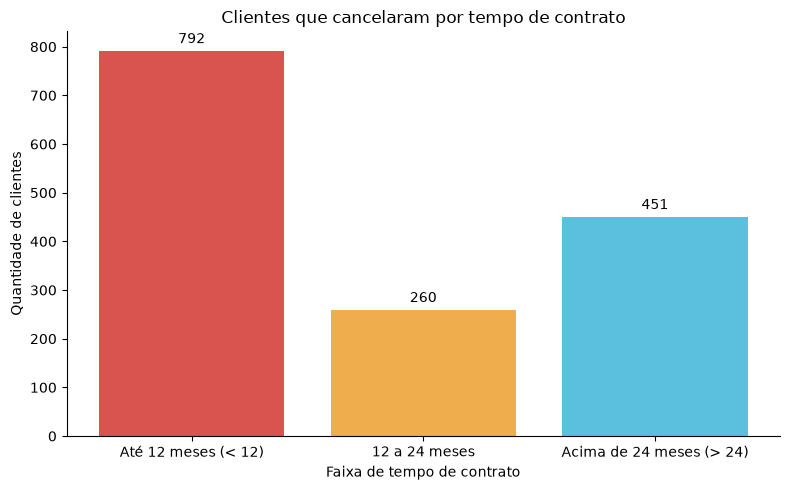

In [112]:
import matplotlib.pyplot as plt

t = df_carteira_cancelada["tempo_de_contrato"]

contagem = {
    "Até 12 meses (< 12)": (t < 12).sum(),
    "12 a 24 meses": ((t >= 12) & (t <= 24)).sum(),
    "Acima de 24 meses (> 24)": (t > 24).sum(),
}

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(contagem.keys(), contagem.values(), color=["#d9534f", "#f0ad4e", "#5bc0de"])

ax.bar_label(barras, padding=3)  # mostra o valor em cima de cada barra
ax.set_title("Clientes que cancelaram por tempo de contrato")
ax.set_ylabel("Quantidade de clientes")
ax.set_xlabel("Faixa de tempo de contrato")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

                      faixa  cobranca_total_todos  cobranca_total_cancelados  \
0       Até 12 meses (< 12)             406037.05                  204823.75   
1             12 a 24 meses             930557.25                  328894.10   
2  Acima de 24 meses (> 24)           10831611.85                 1672417.00   

    diferenca  
0   201213.30  
1   601663.15  
2  9159194.85  


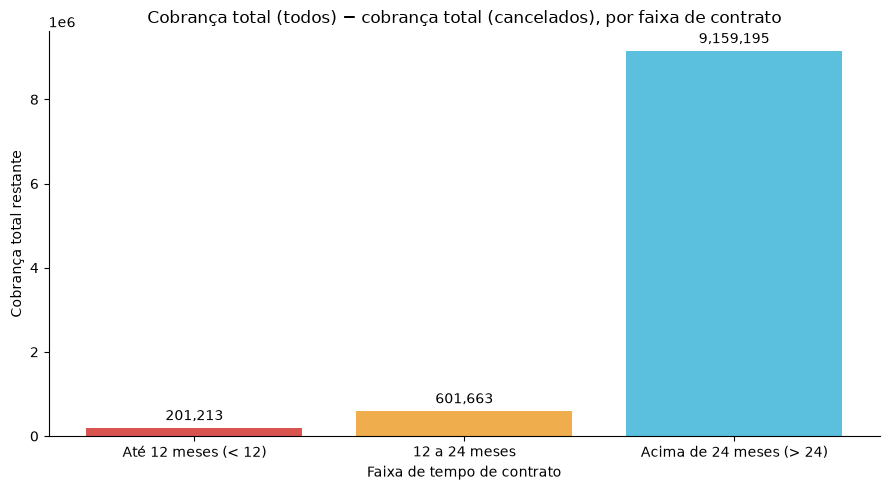

In [113]:
import matplotlib.pyplot as plt

df_base = df_carteira_cliente_traduzido   # todos os clientes
df_canc = df_carteira_cancelada           # só os que cancelaram

faixas = {
    "Até 12 meses (< 12)":        lambda t: t < 12,
    "12 a 24 meses":              lambda t: (t >= 12) & (t <= 24),
    "Acima de 24 meses (> 24)":   lambda t: t > 24,
}

nomes, total_base, total_canc, diferenca = [], [], [], []

for nome, regra in faixas.items():
    m_base = regra(df_base["tempo_de_contrato"]).fillna(False).astype(bool)
    m_canc = regra(df_canc["tempo_de_contrato"]).fillna(False).astype(bool)

    soma_base = df_base.loc[m_base, "cobranca_total"].sum()
    soma_canc = df_canc.loc[m_canc, "cobranca_total"].sum()

    nomes.append(nome)
    total_base.append(soma_base)
    total_canc.append(soma_canc)
    diferenca.append(soma_base - soma_canc)

# tabela de conferência
print(pd.DataFrame({
    "faixa": nomes,
    "cobranca_total_todos": total_base,
    "cobranca_total_cancelados": total_canc,
    "diferenca": diferenca,
}).round(2))

# gráfico
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.bar(nomes, diferenca, color=["#d9534f", "#f0ad4e", "#5bc0de"])

ax.bar_label(barras, labels=[f"{v:,.0f}" for v in diferenca], padding=3)
ax.set_title("Cobrança total (todos) − cobrança total (cancelados), por faixa de contrato")
ax.set_ylabel("Cobrança total restante")
ax.set_xlabel("Faixa de tempo de contrato")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

                      faixa  clientes  receita_mensal_perdida  \
0       Até 12 meses (< 12)       792                52586.25   
1             12 a 24 meses       260                20331.60   
2  Acima de 24 meses (> 24)       451                39218.95   

   perda_contratual  total_perdido  
0           2126.75       54713.00  
1              0.00       20331.60  
2              0.00       39218.95  

Receita mensal perdida total: 112136.8
Perda contratual total:       2126.75


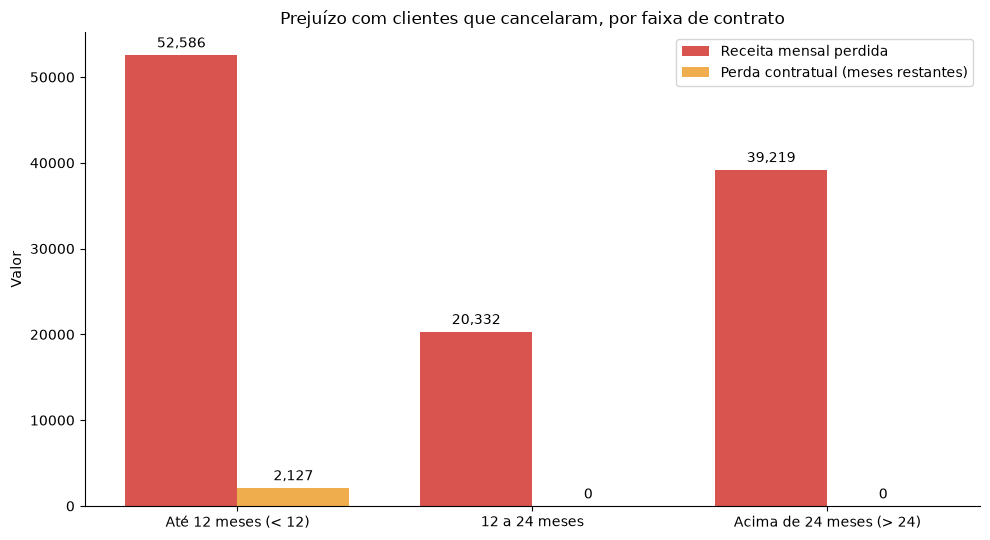

In [114]:
import numpy as np
import matplotlib.pyplot as plt

df_canc = df_carteira_cancelada.copy()

# duração contratual em meses
duracao = df_canc["tipo_de_contrato"].astype(str).map(
    {"month-to-month": 0, "one year": 12, "two year": 24}
)
tempo = df_canc["tempo_de_contrato"].astype("float")

# meses que ainda faltavam no contrato (nunca negativo)
df_canc["meses_restantes"] = (duracao - tempo).clip(lower=0)
df_canc["perda_contratual"] = df_canc["meses_restantes"] * df_canc["cobranca_mensal"]

faixas = {
    "Até 12 meses (< 12)":      lambda t: t < 12,
    "12 a 24 meses":            lambda t: (t >= 12) & (t <= 24),
    "Acima de 24 meses (> 24)": lambda t: t > 24,
}

linhas = []
for nome, regra in faixas.items():
    m = regra(tempo).fillna(False).astype(bool)
    linhas.append({
        "faixa": nome,
        "clientes": m.sum(),
        "receita_mensal_perdida": df_canc.loc[m, "cobranca_mensal"].sum(),
        "perda_contratual": df_canc.loc[m, "perda_contratual"].sum(),
    })

df_prejuizo = pd.DataFrame(linhas)
df_prejuizo["total_perdido"] = df_prejuizo["receita_mensal_perdida"] + df_prejuizo["perda_contratual"]
print(df_prejuizo.round(2))
print("\nReceita mensal perdida total:", round(df_prejuizo["receita_mensal_perdida"].sum(), 2))
print("Perda contratual total:      ", round(df_prejuizo["perda_contratual"].sum(), 2))

# gráfico agrupado
x = np.arange(len(df_prejuizo))
w = 0.38

fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - w/2, df_prejuizo["receita_mensal_perdida"], w,
            label="Receita mensal perdida", color="#d9534f")
b2 = ax.bar(x + w/2, df_prejuizo["perda_contratual"], w,
            label="Perda contratual (meses restantes)", color="#f0ad4e")

ax.bar_label(b1, labels=[f"{v:,.0f}" for v in df_prejuizo["receita_mensal_perdida"]], padding=3)
ax.bar_label(b2, labels=[f"{v:,.0f}" for v in df_prejuizo["perda_contratual"]], padding=3)

ax.set_xticks(x)
ax.set_xticklabels(df_prejuizo["faixa"])
ax.set_title("Prejuízo com clientes que cancelaram, por faixa de contrato")
ax.set_ylabel("Valor")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [115]:
%pip install pyarrow
import pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [118]:
df_carteira_cliente_traduzido.to_parquet("df_carteira_cliente_traduzido.parquet", index=False)

In [119]:
df_carteira_cliente_traduzido = pd.read_parquet("df_carteira_cliente_traduzido.parquet")